# Experiment 1: Loading Data from CSV, JSON and Excel Formats

**A52 Dipanshu Ambilkar**

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [2]:
np.random.seed(1)
n = 120
df = pd.DataFrame({
    "OrderID": range(1, n + 1),
    "Product": np.random.choice(["Laptop", "Phone", "Tablet", "Headphones"], n),
    "Category": np.random.choice(["Electronics", "Accessories"], n),
    "Quantity": np.random.randint(1, 5, n),
    "Price": np.random.choice([999, 1499, 2499, 4999, 12999], n),
    "Region": np.random.choice(["North", "South", "East", "West"], n),
})
df.loc[np.random.choice(n, 8), "Price"] = np.nan
df = pd.concat([df, df.iloc[:5]], ignore_index=True)

In [3]:
df.to_csv("sales.csv", index=False)
df.to_excel("sales.xlsx", index=False)
df.to_json("sales.json", orient="records")

In [4]:
c = pd.read_csv("sales.csv")
e = pd.read_excel("sales.xlsx")
j = pd.read_json("sales.json")
print(c.shape, e.shape, j.shape)
print(c.isnull().sum())

(125, 6) (125, 6) (125, 6)
OrderID     0
Product     0
Category    0
Quantity    0
Price       8
Region      0
dtype: int64


In [5]:
c = c.drop_duplicates()
c["Price"] = c["Price"].fillna(c["Price"].median())
e = e.drop_duplicates()
e["Price"] = e["Price"].fillna(e["Price"].median())

In [6]:
c["Total"] = c["Quantity"] * c["Price"]
print(c.describe())
print("Total sales:", c["Total"].sum())
print("Avg order value:", c["Total"].mean())
print(c.groupby("Category")["Total"].sum())

          OrderID    Quantity         Price         Total
count  120.000000  120.000000    120.000000    120.000000
mean    60.500000    2.500000   4778.166667  11180.833333
std     34.785054    1.173947   4610.362749  12336.461920
min      1.000000    1.000000    999.000000    999.000000
25%     30.750000    1.000000   1499.000000   2997.000000
50%     60.500000    3.000000   2499.000000   5996.000000
75%     90.250000    4.000000   4999.000000  12999.000000
max    120.000000    4.000000  12999.000000  51996.000000
Total sales: 1341700.0
Avg order value: 11180.833333333334
Category
Accessories    693855.0
Electronics    647845.0
Name: Total, dtype: float64


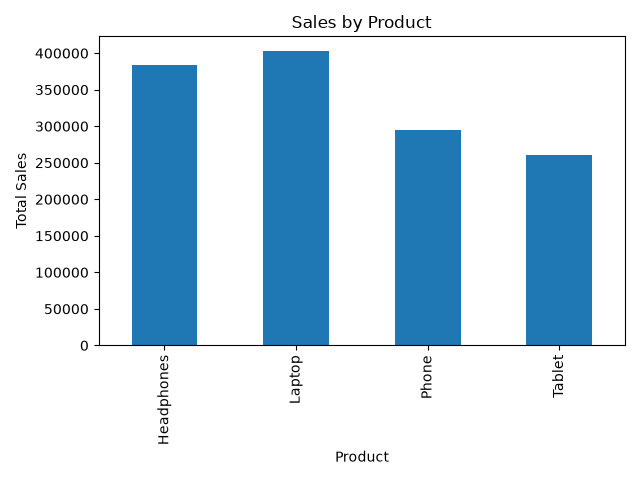

In [7]:
c.groupby("Product")["Total"].sum().plot(kind="bar")
plt.title("Sales by Product")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("sales_bar.png")
display(Image("sales_bar.png"))
plt.close()

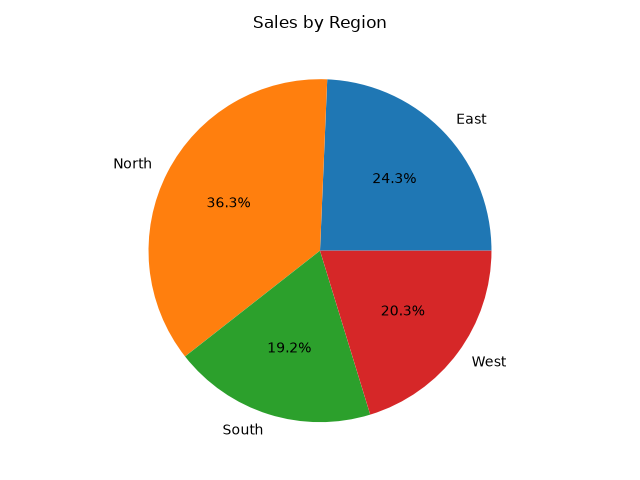

In [8]:
c.groupby("Region")["Total"].sum().plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by Region")
plt.ylabel("")
plt.tight_layout()
plt.savefig("sales_pie.png")
display(Image("sales_pie.png"))
plt.close()

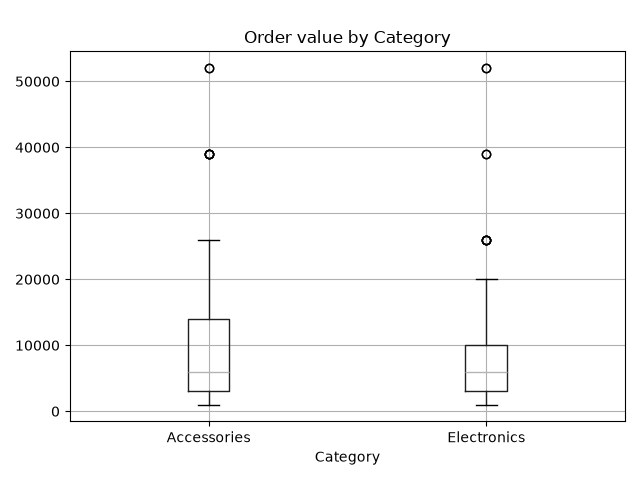

done


In [9]:
c.boxplot(column="Total", by="Category")
plt.title("Order value by Category")
plt.suptitle("")
plt.tight_layout()
plt.savefig("sales_box.png")
display(Image("sales_box.png"))
plt.close()
print("done")